# Comparing Different Search Strategies: Maze

Notes on breaking ties: 

* The order in which the children are explored (see `available directions`) makes a big difference for DFS and dealing with empty spaces. I explore the directions in random order which makes the algorithm stochastic!
* Ties for $h(n)$ and $f(n)$ need to be broken in a consistent manner. I use the most recently added node. To try to keep moving into the same direction.



In [1]:
import importlib
import tree_search_solution as ts
importlib.reload(ts)

<module 'tree_search_solution' from 'd:\\lab02 - Searching\\tree_search_solution.py'>

Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).
Position(0,0): X
Position(8,1):  


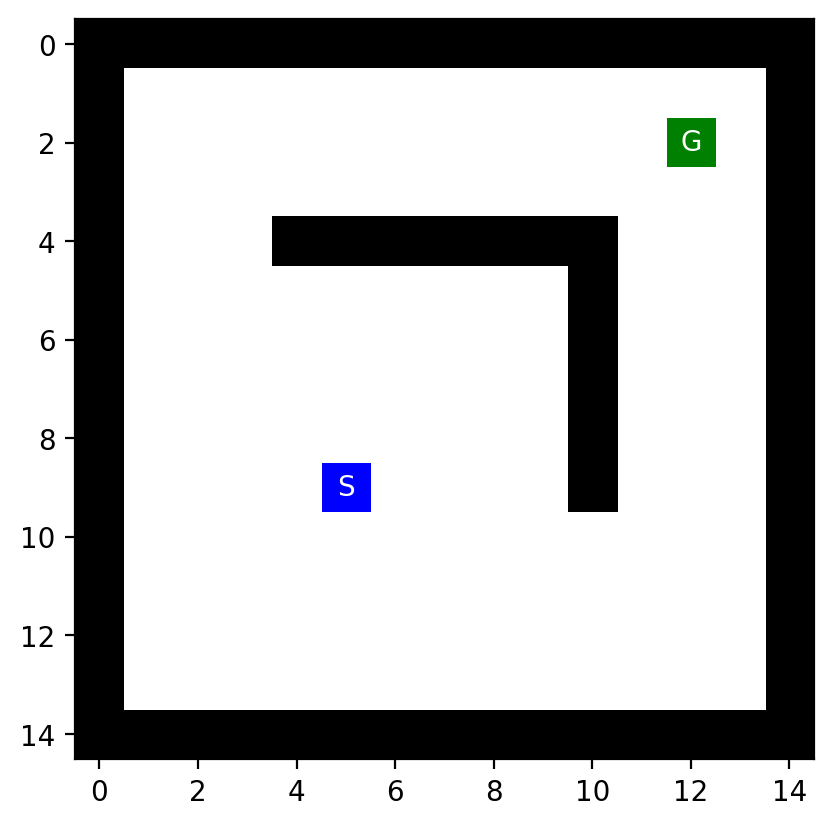

In [2]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

# look at two positions in the maze
print("Position(0,0):", maze[0, 0])
print("Position(8,1):", maze[8, 1])

show_maze(maze)

## Implementation

My implementation follows the pseudo code from the slides/textbook.

In [3]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## Experiments

### BFS

CPU times: total: 46.9 ms
Wall time: 52.1 ms
Path length: 16
Reached squares: 152
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E']
Max depth: 16
Max frontier: 1067


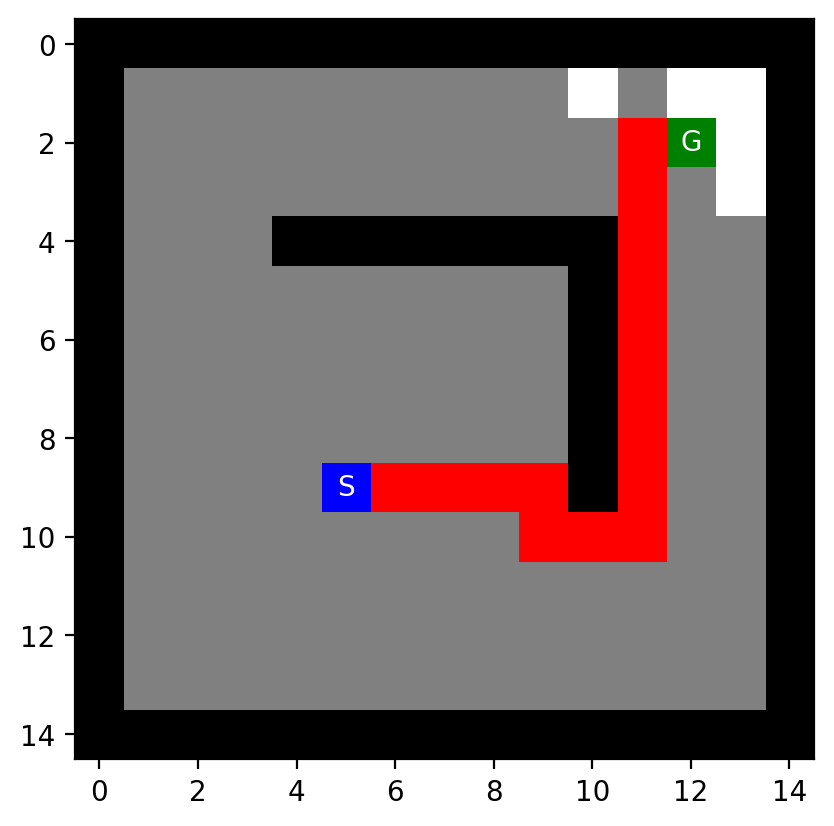

['E',
 'E',
 'E',
 'E',
 'S',
 'E',
 'E',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'E']

In [4]:
ts.set_order("NESW")
#ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "BFS", debug = False, vis = False)
ts.show_path(maze, result)
result['actions']

### DFS 

This implementation uses not reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we will end up in an infinite loop. Here are possible solutions:
* Stop after a fixed number of tries and return no solution `max_tries`.
* IDS solves this problem.

Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory!

CPU times: total: 0 ns
Wall time: 718 μs
Path length: 24
Reached squares: 157
Action sequence: ['N', 'N', 'N', 'N', 'E', 'E', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E']
Max depth: 80
Max frontier: 60


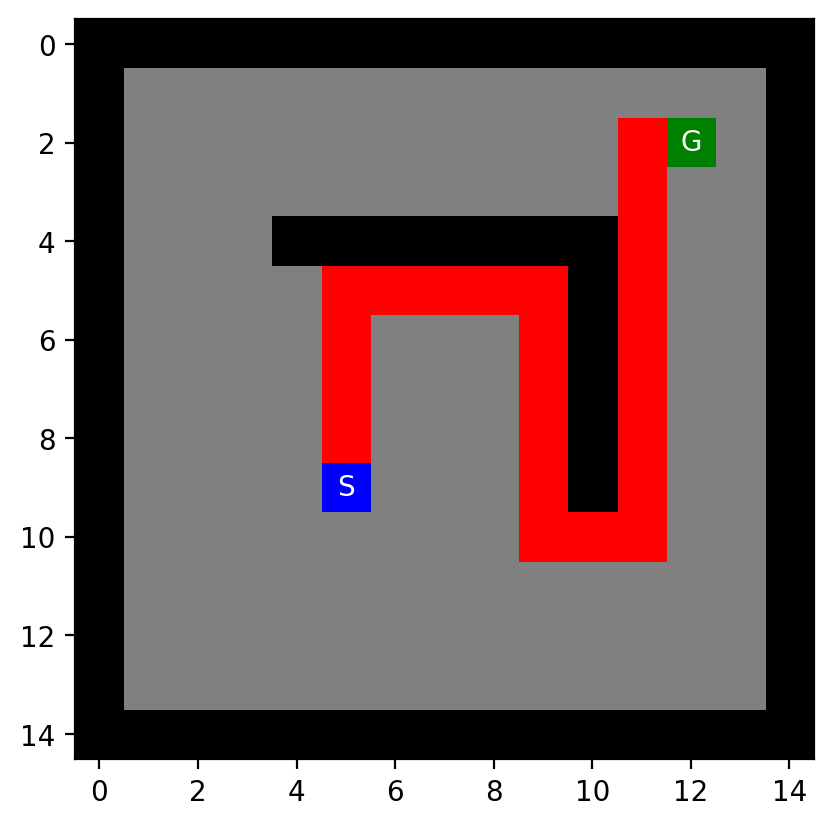

In [5]:
# Note: DFS uses LIFO so the directions come from the stack in reverse order!

# Can get stuck for empty maze since cycle checking is not string enough! 
# I use a maximum number of tries and stop if the goal is not reached.
ts.set_order("NESW")
#ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

Do the same, but change the order in which we explore states (add them to them as nodes to the frontier).

CPU times: total: 0 ns
Wall time: 1.19 ms
Path length: 24
Reached squares: 157
Action sequence: ['S', 'S', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'W']
Max depth: 93
Max frontier: 59


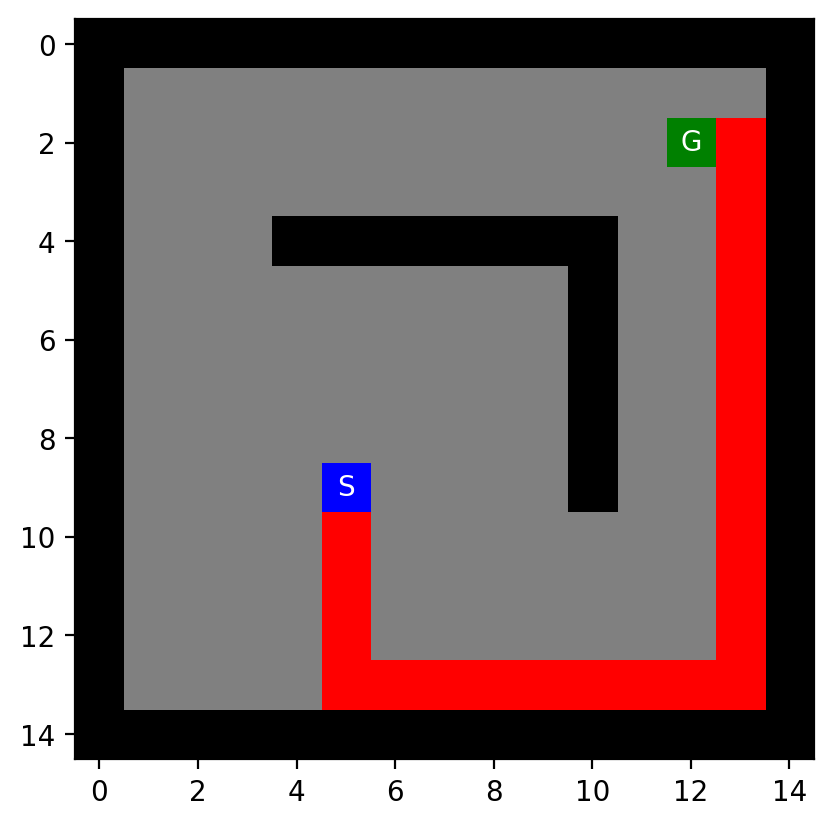

In [6]:
#ts.set_order("NESW")
ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

We could do a random walk and not check for cycles. This is guaranteed to reach eventually any square including the goal, 
but creates a long path. The path could be simplified leading to the [Tremaux's algorithm](https://en.wikipedia.org/wiki/Maze_solving_algorithm).

CPU times: total: 15.6 ms
Wall time: 14.3 ms
Path length: 1464
Reached squares: 0
Action sequence: ['E', 'N', 'N', 'S', 'S', 'N', 'W', 'W', 'N', 'W', 'W', 'S', 'S', 'E', 'S', 'W', 'S', 'W', 'S', 'S', 'N', 'E', 'S', 'N', 'E', 'W', 'N', 'S', 'S', 'W', 'N', 'S', 'E', 'N', 'E', 'N', 'E', 'S', 'S', 'N', 'N', 'N', 'S', 'E', 'W', 'W', 'W', 'N', 'S', 'N', 'S', 'W', 'E', 'S', 'S', 'E', 'E', 'E', 'E', 'N', 'N', 'N', 'S', 'S', 'N', 'E', 'W', 'E', 'S', 'E', 'N', 'W', 'N', 'S', 'E', 'S', 'S', 'W', 'N', 'S', 'E', 'W', 'W', 'W', 'N', 'N', 'N', 'E', 'W', 'S', 'E', 'S', 'N', 'W', 'W', 'E', 'W', 'S', 'W', 'W', 'W', 'E', 'N', 'W', 'E', 'E', 'W', 'W', 'E', 'S', 'W', 'E', 'S', 'E', 'E', 'N', 'W', 'W', 'N', 'W', 'S', 'S', 'N', 'S', 'N', 'S', 'N', 'S', 'E', 'W', 'N', 'E', 'E', 'E', 'E', 'N', 'W', 'S', 'W', 'S', 'N', 'S', 'N', 'N', 'S', 'N', 'S', 'N', 'E', 'S', 'W', 'E', 'N', 'S', 'S', 'N', 'S', 'N', 'N', 'N', 'E', 'S', 'W', 'N', 'S', 'E', 'W', 'W', 'N', 'N', 'W', 'W', 'N', 'N', 'N', 'E', 'S', 'S', 'E', 'N', 

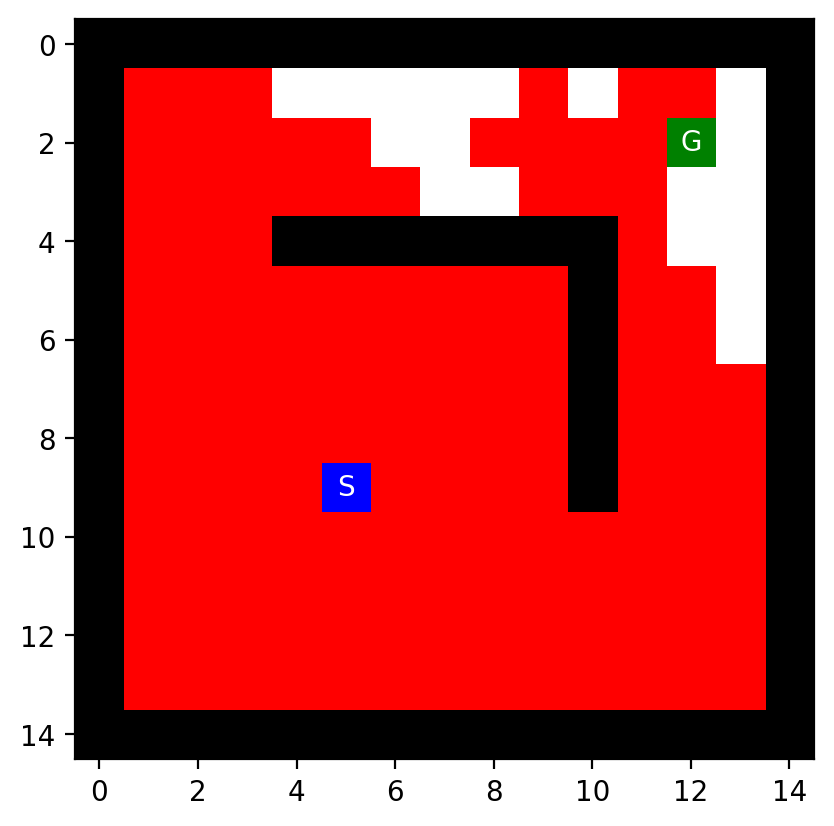

CPU times: total: 0 ns
Wall time: 643 μs
Path length: 88
Reached squares: 0
Action sequence: ['E', 'S', 'S', 'E', 'E', 'N', 'W', 'S', 'E', 'N', 'N', 'S', 'S', 'N', 'N', 'E', 'S', 'S', 'E', 'W', 'E', 'S', 'E', 'W', 'E', 'W', 'E', 'N', 'N', 'S', 'S', 'S', 'N', 'W', 'W', 'E', 'N', 'E', 'S', 'S', 'N', 'N', 'N', 'N', 'E', 'S', 'S', 'E', 'N', 'S', 'W', 'N', 'E', 'S', 'N', 'W', 'E', 'N', 'N', 'N', 'N', 'S', 'W', 'S', 'W', 'N', 'N', 'S', 'E', 'E', 'N', 'N', 'N', 'S', 'N', 'W', 'W', 'S', 'E', 'N', 'E', 'S', 'S', 'N', 'N', 'N', 'N', 'W']
Max depth: 88
Max frontier: 230


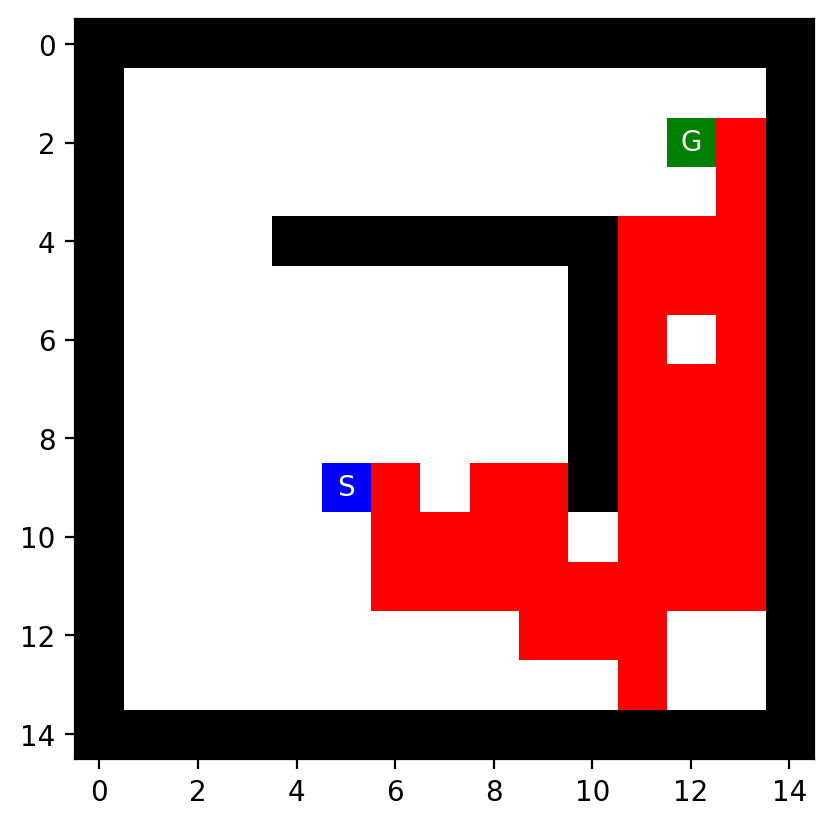

CPU times: total: 0 ns
Wall time: 1.9 ms
Path length: 288
Reached squares: 0
Action sequence: ['E', 'W', 'W', 'S', 'W', 'N', 'E', 'W', 'E', 'E', 'W', 'N', 'N', 'S', 'W', 'S', 'S', 'E', 'E', 'W', 'W', 'E', 'N', 'W', 'N', 'E', 'W', 'E', 'W', 'N', 'S', 'W', 'S', 'E', 'E', 'S', 'E', 'N', 'W', 'N', 'W', 'E', 'S', 'S', 'N', 'S', 'E', 'S', 'E', 'N', 'S', 'W', 'W', 'W', 'E', 'N', 'S', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'S', 'S', 'E', 'N', 'N', 'N', 'E', 'E', 'W', 'N', 'N', 'S', 'E', 'S', 'E', 'W', 'N', 'E', 'N', 'N', 'N', 'W', 'E', 'W', 'S', 'W', 'E', 'E', 'N', 'S', 'N', 'N', 'S', 'N', 'S', 'N', 'W', 'S', 'E', 'W', 'E', 'W', 'S', 'S', 'E', 'N', 'W', 'N', 'E', 'S', 'W', 'N', 'W', 'E', 'S', 'S', 'E', 'N', 'W', 'W', 'S', 'E', 'N', 'E', 'S', 'W', 'W', 'E', 'E', 'S', 'S', 'N', 'W', 'N', 'E', 'W', 'W', 'S', 'E', 'E', 'S', 'W', 'W', 'S', 'S', 'S', 'N', 'S', 'E', 'N', 'W', 'W', 'E', 'W', 'S', 'W', 'W', 'E', 'E', 'W', 'W', 'E', 'E', 'W', 'W', 'W', 'E', 'E', 'E', 'E', 'W', 'E', 'N', 'E', 'N', 'W', 'W', 

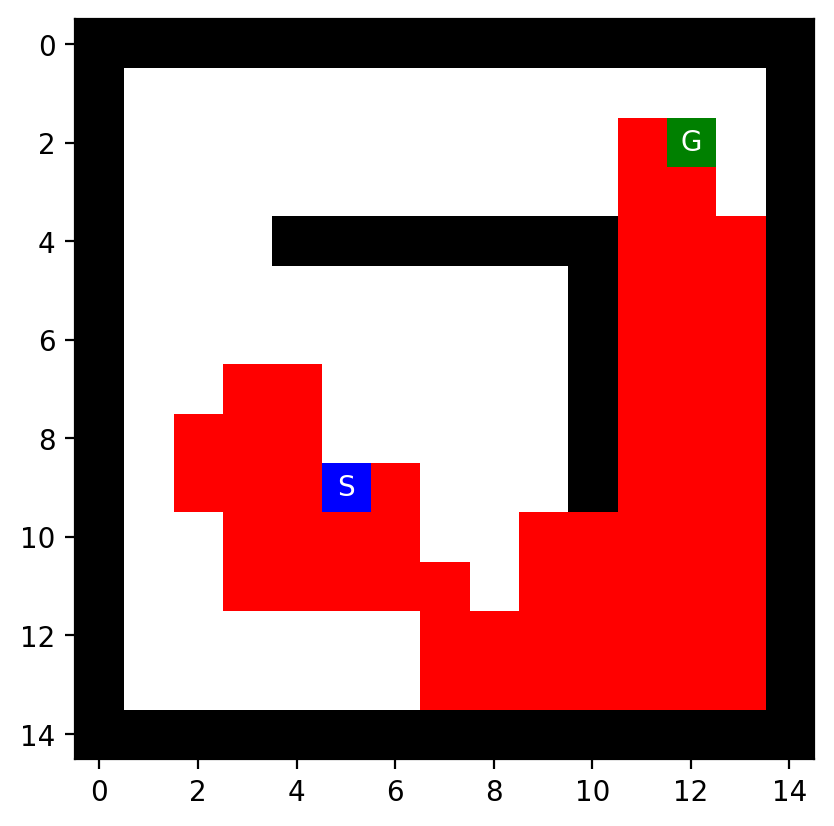

CPU times: total: 0 ns
Wall time: 7.38 ms
Path length: 1036
Reached squares: 0
Action sequence: ['N', 'S', 'S', 'N', 'N', 'S', 'N', 'W', 'W', 'E', 'W', 'E', 'S', 'W', 'E', 'E', 'S', 'E', 'E', 'W', 'N', 'E', 'W', 'W', 'E', 'W', 'S', 'N', 'W', 'S', 'N', 'W', 'E', 'E', 'S', 'N', 'W', 'E', 'N', 'W', 'S', 'S', 'S', 'W', 'W', 'N', 'W', 'N', 'E', 'E', 'N', 'E', 'E', 'N', 'N', 'N', 'W', 'S', 'N', 'S', 'E', 'E', 'W', 'W', 'N', 'E', 'S', 'E', 'W', 'S', 'E', 'E', 'S', 'E', 'E', 'N', 'N', 'N', 'S', 'S', 'S', 'S', 'N', 'N', 'N', 'S', 'N', 'N', 'S', 'N', 'S', 'S', 'N', 'W', 'E', 'S', 'N', 'W', 'W', 'N', 'E', 'W', 'S', 'E', 'E', 'W', 'W', 'S', 'N', 'W', 'E', 'W', 'N', 'S', 'N', 'S', 'W', 'E', 'W', 'S', 'S', 'E', 'W', 'S', 'W', 'W', 'E', 'E', 'E', 'E', 'N', 'N', 'S', 'E', 'W', 'E', 'W', 'N', 'W', 'S', 'W', 'W', 'S', 'E', 'W', 'S', 'W', 'N', 'N', 'E', 'E', 'S', 'W', 'S', 'N', 'S', 'W', 'E', 'E', 'S', 'W', 'E', 'N', 'W', 'N', 'E', 'E', 'E', 'E', 'N', 'N', 'S', 'E', 'W', 'E', 'S', 'N', 'S', 'N', 'S', 'W'

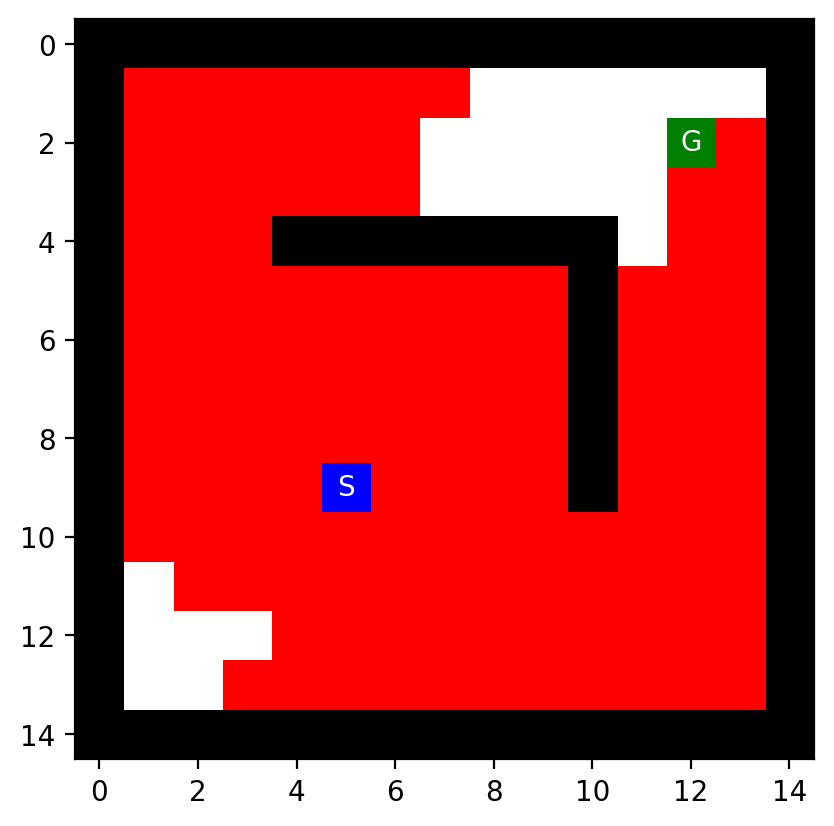

CPU times: total: 15.6 ms
Wall time: 7.45 ms
Path length: 662
Reached squares: 0
Action sequence: ['N', 'W', 'E', 'W', 'W', 'S', 'E', 'S', 'W', 'S', 'N', 'W', 'E', 'E', 'W', 'S', 'S', 'W', 'S', 'N', 'E', 'W', 'N', 'N', 'E', 'E', 'N', 'W', 'S', 'S', 'W', 'N', 'S', 'S', 'E', 'S', 'W', 'E', 'W', 'E', 'N', 'N', 'E', 'S', 'N', 'N', 'S', 'W', 'E', 'N', 'W', 'E', 'N', 'E', 'N', 'E', 'S', 'W', 'S', 'N', 'W', 'S', 'N', 'W', 'E', 'W', 'S', 'S', 'W', 'N', 'W', 'S', 'E', 'E', 'N', 'W', 'E', 'S', 'S', 'E', 'W', 'E', 'W', 'N', 'E', 'N', 'N', 'W', 'E', 'N', 'S', 'E', 'E', 'S', 'N', 'E', 'S', 'N', 'N', 'S', 'W', 'W', 'E', 'S', 'S', 'N', 'W', 'S', 'N', 'S', 'E', 'S', 'N', 'N', 'E', 'S', 'S', 'E', 'N', 'N', 'W', 'E', 'W', 'N', 'W', 'N', 'E', 'E', 'N', 'N', 'W', 'N', 'W', 'S', 'E', 'W', 'S', 'N', 'N', 'W', 'E', 'S', 'S', 'N', 'W', 'N', 'S', 'S', 'W', 'W', 'W', 'S', 'E', 'N', 'W', 'N', 'E', 'S', 'E', 'S', 'E', 'S', 'S', 'S', 'W', 'W', 'N', 'N', 'W', 'E', 'W', 'N', 'E', 'W', 'S', 'W', 'S', 'S', 'E', 'W', '

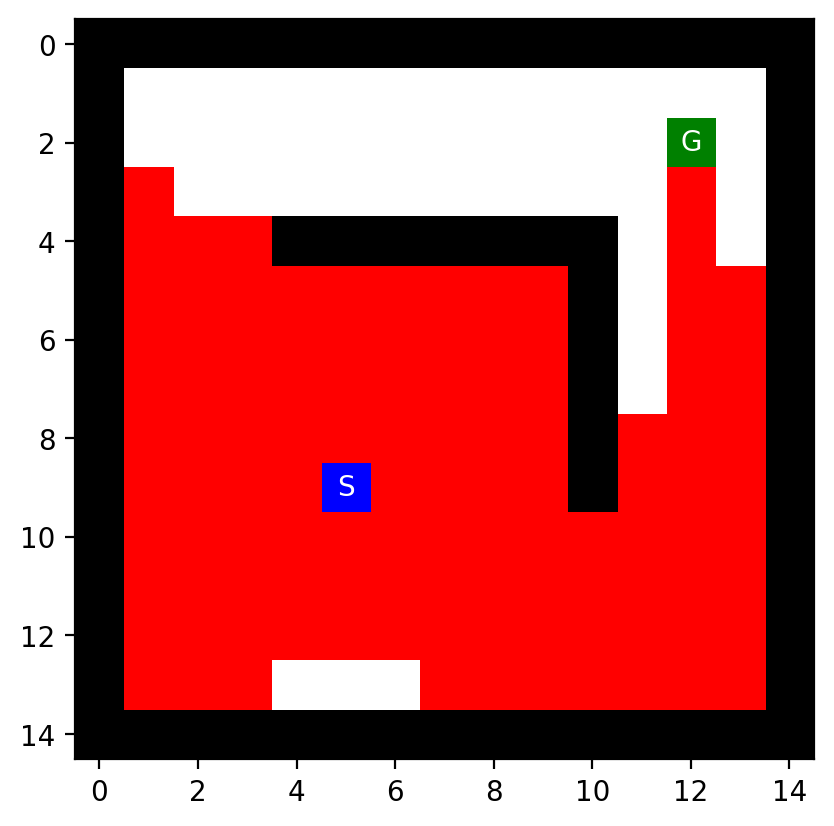

In [7]:
ts.set_order(random = True)

# run it multiple times to see the effect of randomization
for _ in range(5):
    %time result = ts.DFS(maze, check_cycle = False, max_tries = 100000, vis = False, debug_reached = True)

    #result
    ts.show_path(maze, result)
    if result['path'] is None:
        print("No solution found!")

### Run randomized DFS multiple times and use the best solution.

__Note:__ IDS takes a similar amount of time and memory, but is guaranteed optimal.

CPU times: total: 78.1 ms
Wall time: 57.3 ms
Solutions have path_lengths of [36, 58, 54, 74, 56, 54, 62, 54, 48, 36, 28, 28, 52, 40, 52, 50, 36, 28, 24, 32, 48, 40, 46, 30, 54, 58, 22, 28, 48, 22, 40, 26, 26, 48, 58, 48, 42, 46, 52, 62, 40, 54, 54, 28, 38, 46, 28, 26, 42, 32, 56, 32, 58, 52, 44, 44, 42, 26, 40, 36, 54, 56, 46, 28, 40, 40, 46, 42, 28, 46, 60, 50, 48, 28, 50, 46, 52, 32, 28, 36, 28, 58, 38, 38, 50, 52, 54, 64, 44, 24, 56, 48, 48, 60, 68, 38, 60, 58, 46, 56]
Path length: 22
Reached squares: 60
Action sequence: ['E', 'E', 'S', 'S', 'E', 'S', 'E', 'E', 'N', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'N', 'N', 'W', 'N']
Max depth: 28
Max frontier: 27


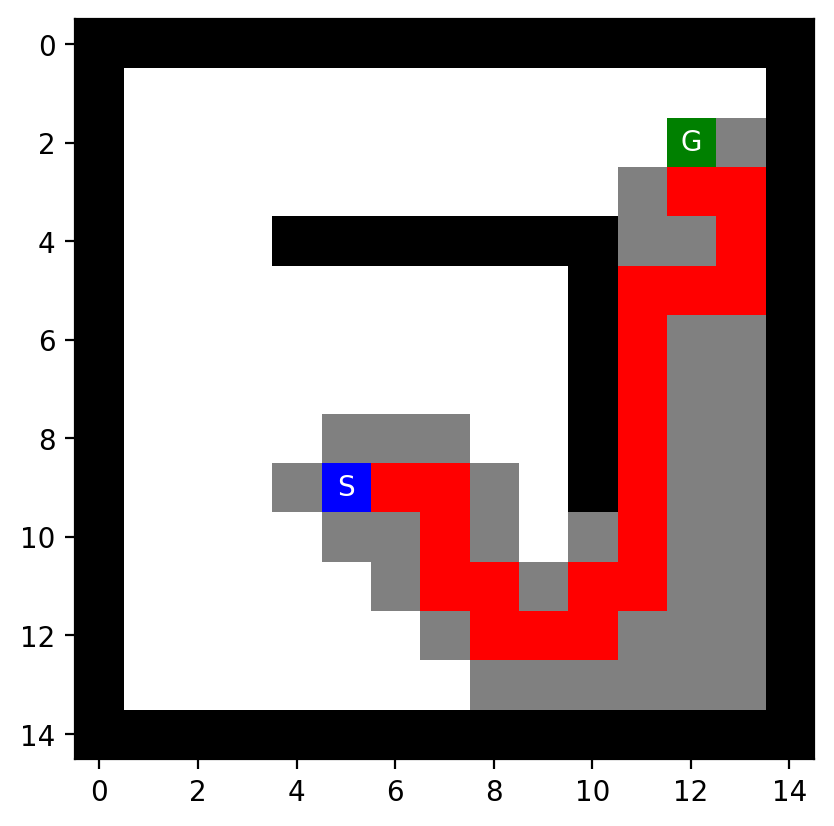

In [8]:
ts.set_order(random = True)

N = 100
%time results = [ ts.DFS(maze, max_tries = 10000, vis = False) for _ in range(N) ]

# check if we found a solution and display the best solution
results = [ r for r in results if not r['path'] is None ]
if len(results) > 0:
    path_lengths = [ len(r['path'])-1 for r in results ]

    print(f"Solutions have path_lengths of {path_lengths}")

    result = results[ts.min_index(path_lengths)]
    ts.show_path(maze, result)
else:
    print("No solution found!")

### Depth limited DFS

Note: The frontier needs to be checked differently during cycle checking!

CPU times: total: 0 ns
Wall time: 479 μs
Path length: 60
Reached squares: 113
Action sequence: ['E', 'S', 'E', 'E', 'S', 'E', 'E', 'N', 'E', 'N', 'E', 'E', 'S', 'S', 'S', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'N', 'W', 'W', 'N', 'W', 'W', 'W', 'W', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'N', 'N', 'N', 'W', 'W', 'N', 'N', 'E', 'E', 'E', 'S', 'E', 'E', 'S', 'E', 'E', 'E', 'E', 'N', 'N', 'E', 'E', 'S']
Max depth: 60
Max frontier: 52


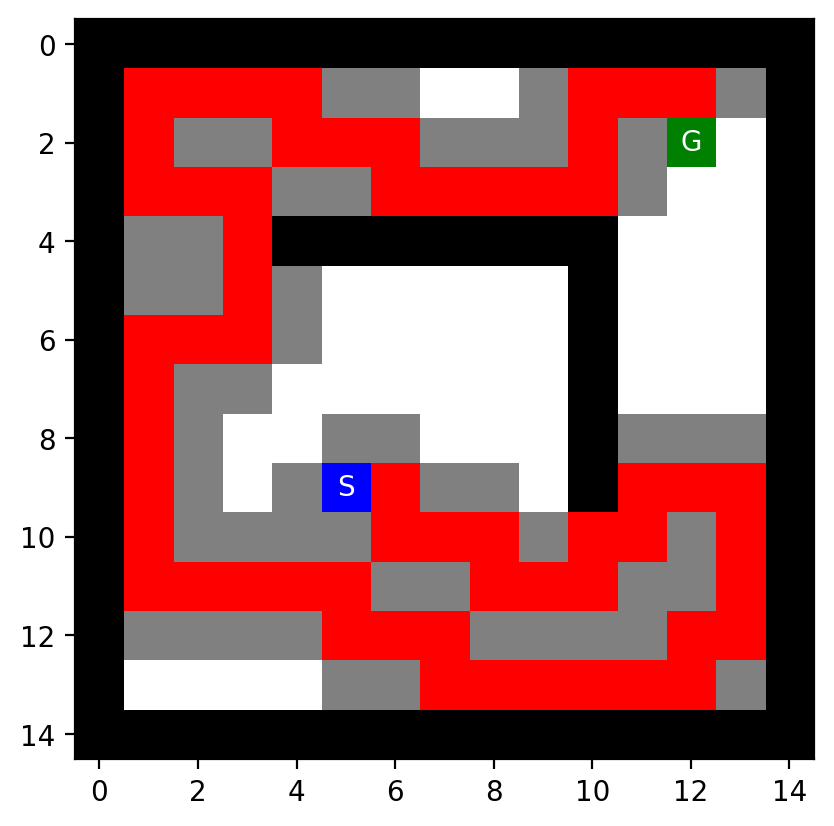

{'path': [(np.int64(9), np.int64(5)),
  (np.int64(9), np.int64(6)),
  (np.int64(10), np.int64(6)),
  (np.int64(10), np.int64(7)),
  (np.int64(10), np.int64(8)),
  (np.int64(11), np.int64(8)),
  (np.int64(11), np.int64(9)),
  (np.int64(11), np.int64(10)),
  (np.int64(10), np.int64(10)),
  (np.int64(10), np.int64(11)),
  (np.int64(9), np.int64(11)),
  (np.int64(9), np.int64(12)),
  (np.int64(9), np.int64(13)),
  (np.int64(10), np.int64(13)),
  (np.int64(11), np.int64(13)),
  (np.int64(12), np.int64(13)),
  (np.int64(12), np.int64(12)),
  (np.int64(13), np.int64(12)),
  (np.int64(13), np.int64(11)),
  (np.int64(13), np.int64(10)),
  (np.int64(13), np.int64(9)),
  (np.int64(13), np.int64(8)),
  (np.int64(13), np.int64(7)),
  (np.int64(12), np.int64(7)),
  (np.int64(12), np.int64(6)),
  (np.int64(12), np.int64(5)),
  (np.int64(11), np.int64(5)),
  (np.int64(11), np.int64(4)),
  (np.int64(11), np.int64(3)),
  (np.int64(11), np.int64(2)),
  (np.int64(11), np.int64(1)),
  (np.int64(10), np.int

In [9]:
ts.set_order(random = True)

%time result = ts.DFS(maze, limit = 5, frontier_option = 2, max_tries = 100000, vis = False, debug_reached = True)
ts.show_path(maze, result)

### IDS

__Notes:__ 

* IDS with DFS does not store reached squares, so gray areas are not shown!

* IDS depends on the cycle checking of DFS and therefore is also affected by these problems.

In [10]:
ts.set_order(random = True)

%time result = ts.IDS(maze, frontier_option = 2, max_tries = 100000)
ts.show_path(maze, result)

CPU times: total: 6.66 s
Wall time: 6.81 s
No solution found.


{'path': None,
 'actions': None,
 'reached': [],
 'states_explored': 1104457,
 'path_length': 0,
 'maze_anim': []}

### Greedy Best-First Search (GBFS)

In [11]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

CPU times: total: 0 ns
Wall time: 733 μs
Path length: 20
Reached squares: 34
Action sequence: ['E', 'N', 'N', 'E', 'E', 'E', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'E', 'N', 'N', 'N', 'N', 'N', 'N']
Max depth: 20
Max frontier: 47


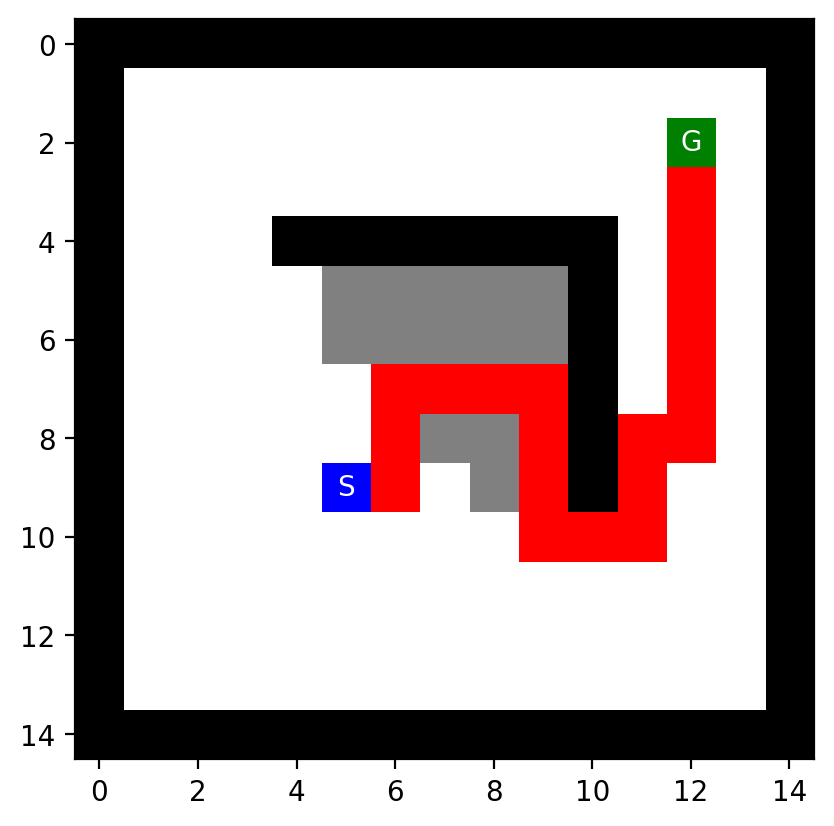

{'path': [(np.int64(9), np.int64(5)),
  (np.int64(9), np.int64(6)),
  (np.int64(8), np.int64(6)),
  (np.int64(7), np.int64(6)),
  (np.int64(7), np.int64(7)),
  (np.int64(7), np.int64(8)),
  (np.int64(7), np.int64(9)),
  (np.int64(8), np.int64(9)),
  (np.int64(9), np.int64(9)),
  (np.int64(10), np.int64(9)),
  (np.int64(10), np.int64(10)),
  (np.int64(10), np.int64(11)),
  (np.int64(9), np.int64(11)),
  (np.int64(8), np.int64(11)),
  (np.int64(8), np.int64(12)),
  (np.int64(7), np.int64(12)),
  (np.int64(6), np.int64(12)),
  (np.int64(5), np.int64(12)),
  (np.int64(4), np.int64(12)),
  (np.int64(3), np.int64(12)),
  (np.int64(2), np.int64(12))],
 'actions': ['E',
  'N',
  'N',
  'E',
  'E',
  'E',
  'S',
  'S',
  'S',
  'E',
  'E',
  'N',
  'N',
  'E',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N'],
 'reached': [(np.int64(6), np.int64(12)),
  (np.int64(4), np.int64(12)),
  (np.int64(5), np.int64(7)),
  (np.int64(9), np.int64(5)),
  (np.int64(8), np.int64(9)),
  (np.int64(9), np.int64(8)),
  

In [12]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "GBFS", debug = False, vis = False)
ts.show_path(maze, result)

### A* Search

CPU times: total: 31.2 ms
Wall time: 29.5 ms
Path length: 16
Reached squares: 54
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'E', 'N', 'N', 'N']
Max depth: 16
Max frontier: 122


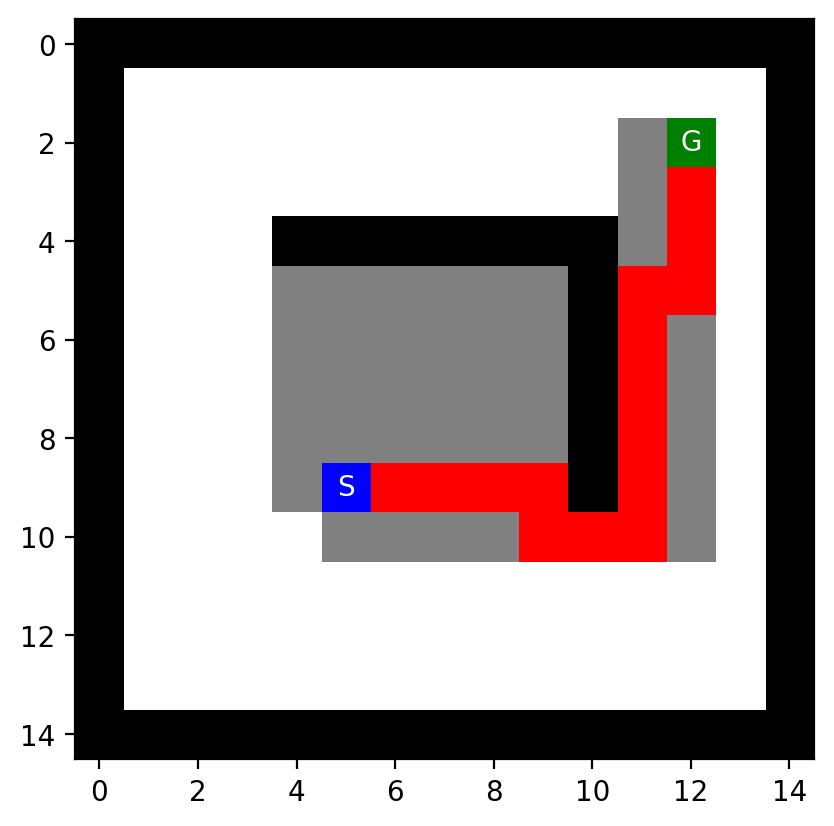

{'path': [(np.int64(9), np.int64(5)),
  (np.int64(9), np.int64(6)),
  (np.int64(9), np.int64(7)),
  (np.int64(9), np.int64(8)),
  (np.int64(9), np.int64(9)),
  (np.int64(10), np.int64(9)),
  (np.int64(10), np.int64(10)),
  (np.int64(10), np.int64(11)),
  (np.int64(9), np.int64(11)),
  (np.int64(8), np.int64(11)),
  (np.int64(7), np.int64(11)),
  (np.int64(6), np.int64(11)),
  (np.int64(5), np.int64(11)),
  (np.int64(5), np.int64(12)),
  (np.int64(4), np.int64(12)),
  (np.int64(3), np.int64(12)),
  (np.int64(2), np.int64(12))],
 'actions': ['E',
  'E',
  'E',
  'E',
  'S',
  'E',
  'E',
  'N',
  'N',
  'N',
  'N',
  'N',
  'E',
  'N',
  'N',
  'N'],
 'reached': [(np.int64(6), np.int64(12)),
  (np.int64(5), np.int64(4)),
  (np.int64(4), np.int64(12)),
  (np.int64(5), np.int64(7)),
  (np.int64(9), np.int64(5)),
  (np.int64(8), np.int64(9)),
  (np.int64(10), np.int64(6)),
  (np.int64(9), np.int64(8)),
  (np.int64(8), np.int64(6)),
  (np.int64(8), np.int64(12)),
  (np.int64(10), np.int64(9)

In [13]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False)
ts.show_path(maze, result)

### Weighted A* Search

$W > 1$ tends towards GBFS (optimality is not guaranteed)

CPU times: total: 15.6 ms
Wall time: 3.14 ms
Path length: 16
Reached squares: 37
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']
Max depth: 16
Max frontier: 38


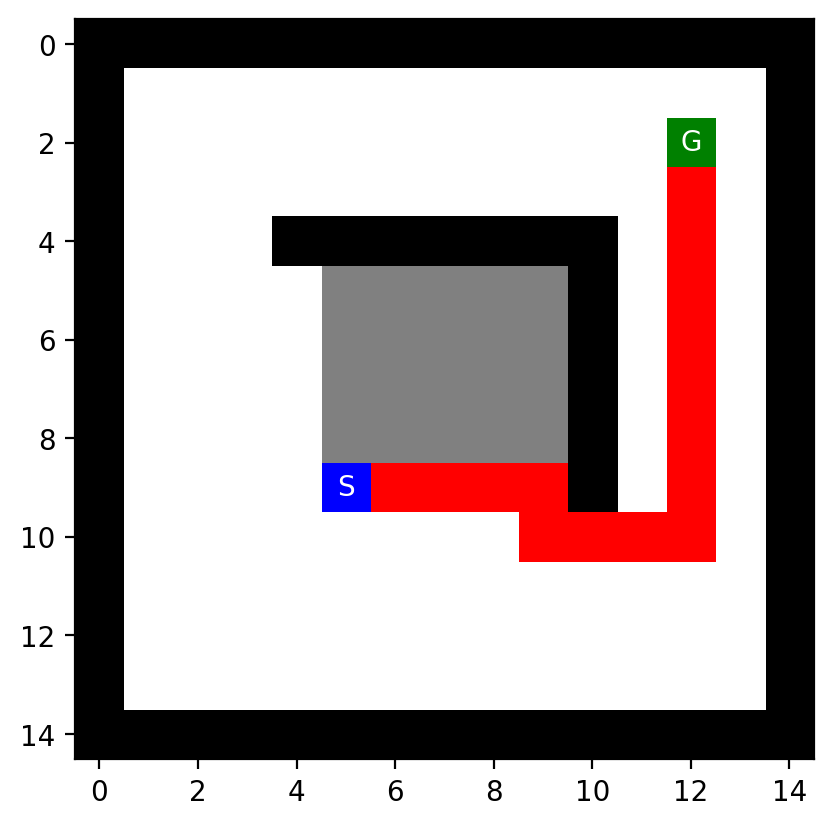

{'path': [(np.int64(9), np.int64(5)),
  (np.int64(9), np.int64(6)),
  (np.int64(9), np.int64(7)),
  (np.int64(9), np.int64(8)),
  (np.int64(9), np.int64(9)),
  (np.int64(10), np.int64(9)),
  (np.int64(10), np.int64(10)),
  (np.int64(10), np.int64(11)),
  (np.int64(10), np.int64(12)),
  (np.int64(9), np.int64(12)),
  (np.int64(8), np.int64(12)),
  (np.int64(7), np.int64(12)),
  (np.int64(6), np.int64(12)),
  (np.int64(5), np.int64(12)),
  (np.int64(4), np.int64(12)),
  (np.int64(3), np.int64(12)),
  (np.int64(2), np.int64(12))],
 'actions': ['E',
  'E',
  'E',
  'E',
  'S',
  'E',
  'E',
  'E',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N'],
 'reached': [(np.int64(6), np.int64(12)),
  (np.int64(4), np.int64(12)),
  (np.int64(5), np.int64(7)),
  (np.int64(9), np.int64(5)),
  (np.int64(8), np.int64(9)),
  (np.int64(9), np.int64(8)),
  (np.int64(8), np.int64(6)),
  (np.int64(8), np.int64(12)),
  (np.int64(10), np.int64(9)),
  (np.int64(10), np.int64(12)),
  (np.int64(7), np.int64(

In [14]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", W = 1+1e-9, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 605 μs
Path length: 16
Reached squares: 31
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']
Max depth: 16
Max frontier: 45


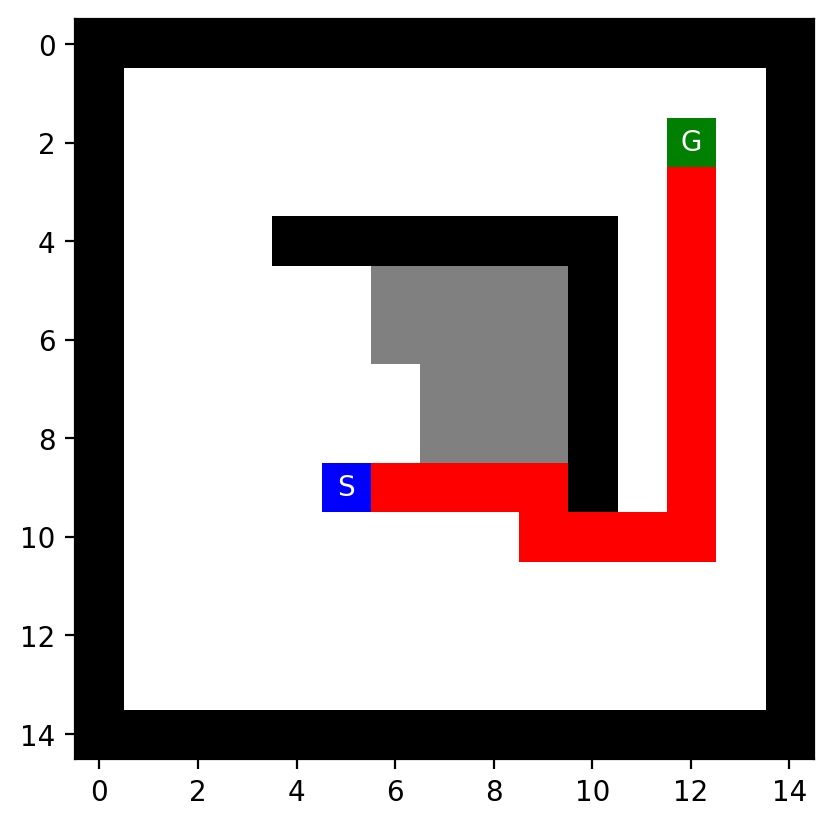

{'path': [(np.int64(9), np.int64(5)),
  (np.int64(9), np.int64(6)),
  (np.int64(9), np.int64(7)),
  (np.int64(9), np.int64(8)),
  (np.int64(9), np.int64(9)),
  (np.int64(10), np.int64(9)),
  (np.int64(10), np.int64(10)),
  (np.int64(10), np.int64(11)),
  (np.int64(10), np.int64(12)),
  (np.int64(9), np.int64(12)),
  (np.int64(8), np.int64(12)),
  (np.int64(7), np.int64(12)),
  (np.int64(6), np.int64(12)),
  (np.int64(5), np.int64(12)),
  (np.int64(4), np.int64(12)),
  (np.int64(3), np.int64(12)),
  (np.int64(2), np.int64(12))],
 'actions': ['E',
  'E',
  'E',
  'E',
  'S',
  'E',
  'E',
  'E',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N'],
 'reached': [(np.int64(6), np.int64(12)),
  (np.int64(4), np.int64(12)),
  (np.int64(5), np.int64(7)),
  (np.int64(9), np.int64(5)),
  (np.int64(8), np.int64(9)),
  (np.int64(9), np.int64(8)),
  (np.int64(8), np.int64(12)),
  (np.int64(10), np.int64(9)),
  (np.int64(10), np.int64(12)),
  (np.int64(7), np.int64(7)),
  (np.int64(6), np.int64(

In [15]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 5, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 946 μs
Path length: 22
Reached squares: 35
Action sequence: ['E', 'N', 'N', 'E', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'E', 'N', 'N', 'N', 'N', 'N', 'N']
Max depth: 22
Max frontier: 64


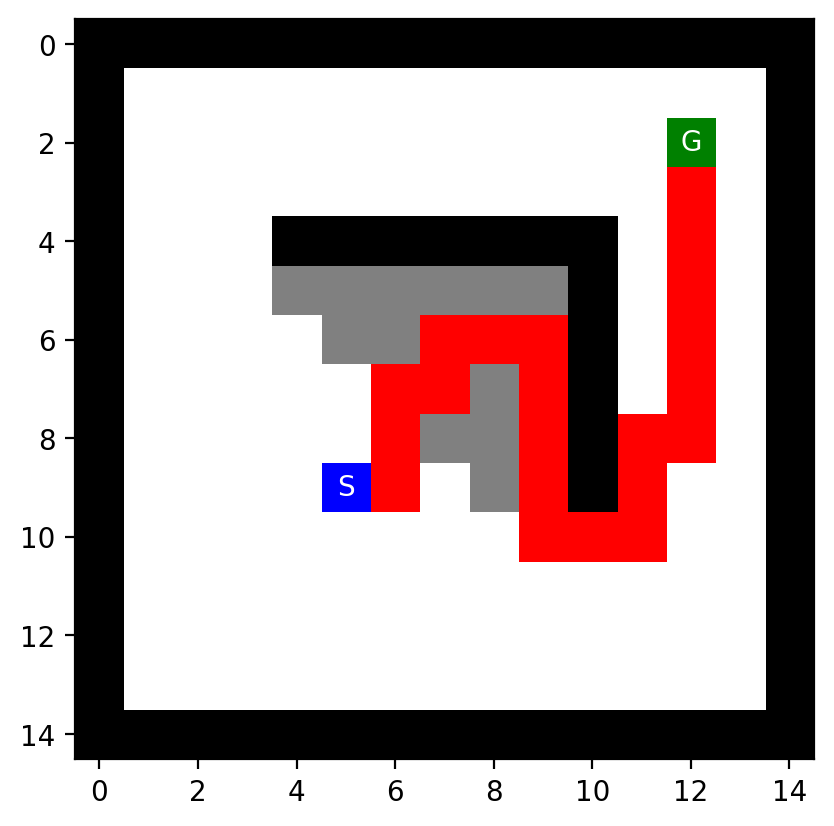

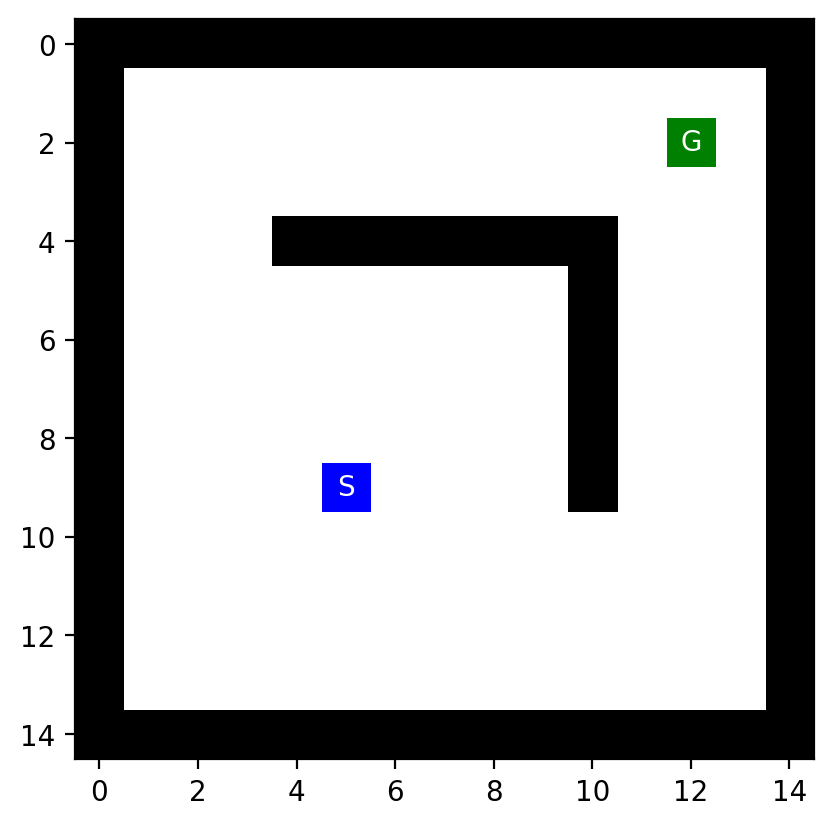

In [16]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 1000, debug = False, vis = False)
ts.show_path(maze, result)
show_maze(maze)

$W<1$ tends towards Uniform-Cost Search/BFS (optimality is guaranteed)

CPU times: total: 312 ms
Wall time: 306 ms
Path length: 16
Reached squares: 89
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'N', 'E', 'N', 'N', 'N', 'N', 'N', 'N']
Max depth: 16
Max frontier: 714


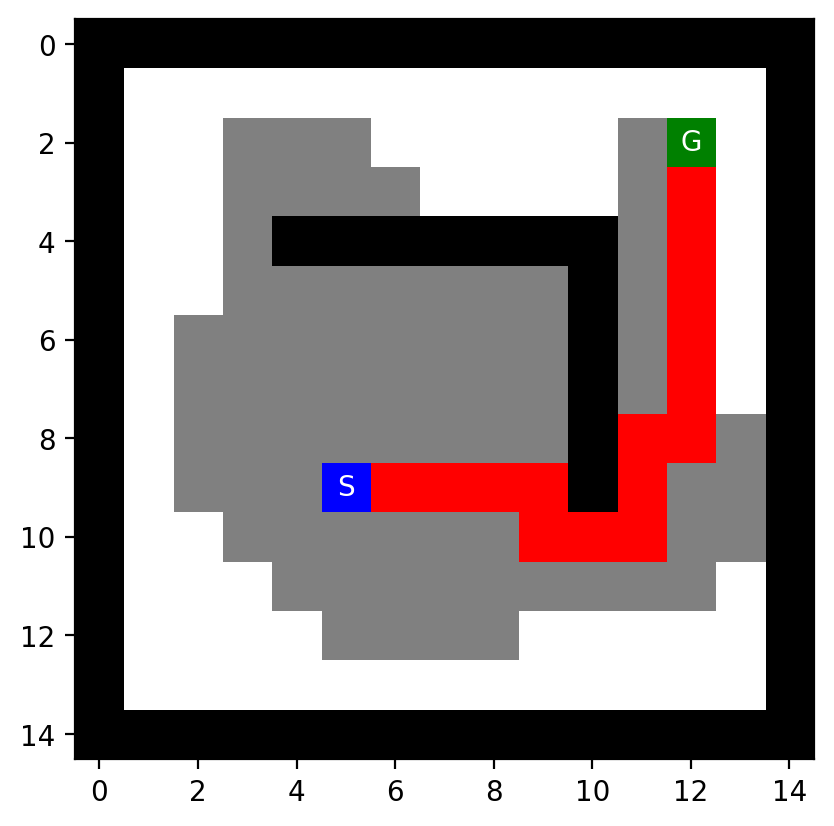

{'path': [(np.int64(9), np.int64(5)),
  (np.int64(9), np.int64(6)),
  (np.int64(9), np.int64(7)),
  (np.int64(9), np.int64(8)),
  (np.int64(9), np.int64(9)),
  (np.int64(10), np.int64(9)),
  (np.int64(10), np.int64(10)),
  (np.int64(10), np.int64(11)),
  (np.int64(9), np.int64(11)),
  (np.int64(8), np.int64(11)),
  (np.int64(8), np.int64(12)),
  (np.int64(7), np.int64(12)),
  (np.int64(6), np.int64(12)),
  (np.int64(5), np.int64(12)),
  (np.int64(4), np.int64(12)),
  (np.int64(3), np.int64(12)),
  (np.int64(2), np.int64(12))],
 'actions': ['E',
  'E',
  'E',
  'E',
  'S',
  'E',
  'E',
  'N',
  'N',
  'E',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N'],
 'reached': [(np.int64(8), np.int64(9)),
  (np.int64(10), np.int64(6)),
  (np.int64(9), np.int64(8)),
  (np.int64(11), np.int64(5)),
  (np.int64(2), np.int64(11)),
  (np.int64(6), np.int64(2)),
  (np.int64(6), np.int64(11)),
  (np.int64(3), np.int64(6)),
  (np.int64(5), np.int64(3)),
  (np.int64(8), np.int64(2)),
  (np.int64(5), np.int64(12)

In [17]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .7, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 4.59 s
Wall time: 4.66 s
Path length: 16
Reached squares: 149
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'N', 'E', 'N', 'N', 'N', 'N', 'N', 'N']
Max depth: 16
Max frontier: 1170


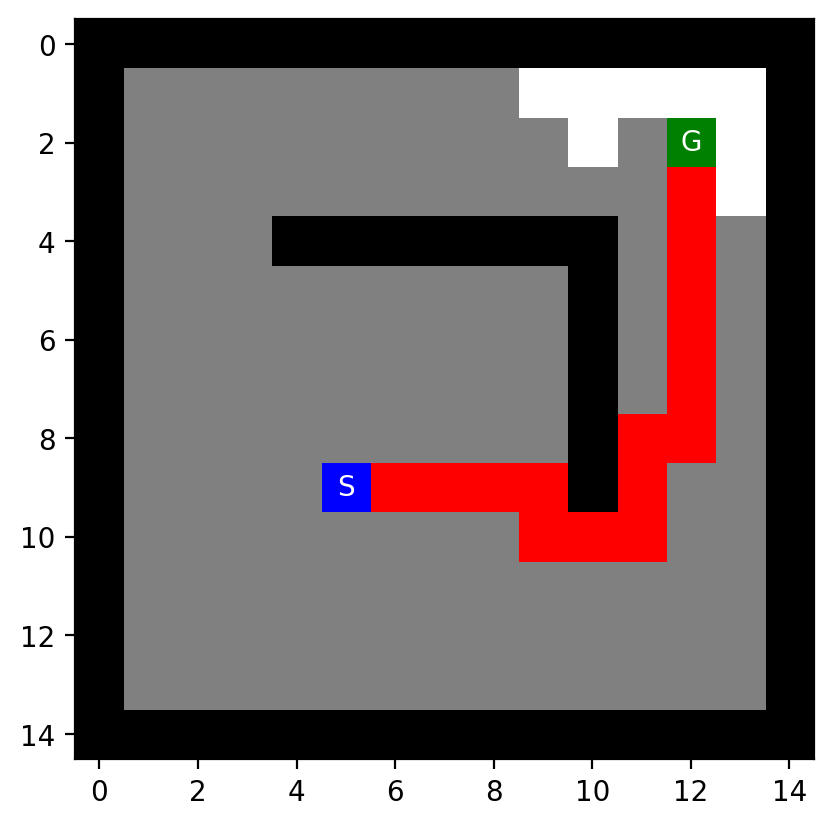

{'path': [(np.int64(9), np.int64(5)),
  (np.int64(9), np.int64(6)),
  (np.int64(9), np.int64(7)),
  (np.int64(9), np.int64(8)),
  (np.int64(9), np.int64(9)),
  (np.int64(10), np.int64(9)),
  (np.int64(10), np.int64(10)),
  (np.int64(10), np.int64(11)),
  (np.int64(9), np.int64(11)),
  (np.int64(8), np.int64(11)),
  (np.int64(8), np.int64(12)),
  (np.int64(7), np.int64(12)),
  (np.int64(6), np.int64(12)),
  (np.int64(5), np.int64(12)),
  (np.int64(4), np.int64(12)),
  (np.int64(3), np.int64(12)),
  (np.int64(2), np.int64(12))],
 'actions': ['E',
  'E',
  'E',
  'E',
  'S',
  'E',
  'E',
  'N',
  'N',
  'E',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N'],
 'reached': [(np.int64(12), np.int64(4)),
  (np.int64(5), np.int64(1)),
  (np.int64(8), np.int64(9)),
  (np.int64(10), np.int64(6)),
  (np.int64(9), np.int64(8)),
  (np.int64(11), np.int64(5)),
  (np.int64(2), np.int64(2)),
  (np.int64(2), np.int64(11)),
  (np.int64(13), np.int64(8)),
  (np.int64(6), np.int64(2)),
  (np.int64(7), np.int64(1)

In [18]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .0001, debug = False, vis = False)
ts.show_path(maze, result)

### Compare Timing

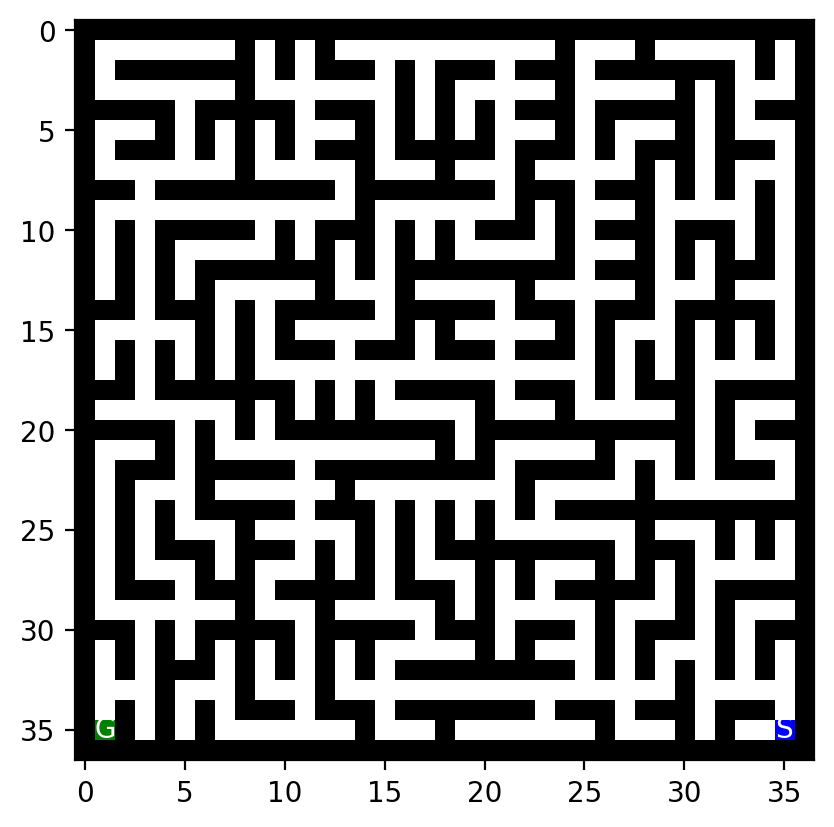

In [19]:
#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("L_maze.txt", "r")
#f = open("loops_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

ts.show_maze(maze)

ts.set_order(random=True)


In [20]:
import timeit
import math

reps = 10

times = {}

algorithms = ["BFS", "DFS", "GBFS", "A*", "IDS"]

for a in algorithms:
    if a == "IDS":
        stmt_str = 'ts.IDS(maze, vis = False)'
    elif a == "DFS":
        stmt_str = 'ts.DFS(maze, vis = False)'
    else:
        stmt_str = f'ts.best_first_search(maze, strategy = "{a}", debug = False, vis = False)'
        
    times[a] = math.ceil(timeit.timeit(stmt = stmt_str, 
                setup = 'from __main__ import ts, maze',
                      number = reps)*1e6/reps)
    
times['DFS(no reached)'] = math.ceil(timeit.timeit(stmt = 'ts.DFS(maze, vis = False, check_cycle = False)', 
                setup = 'from __main__ import ts, maze',
                      number = reps)*1e6/reps)

In [21]:
import pandas as pd
df = pd.DataFrame(times, index = ["time in micro seconds"])
df

,BFS,DFS,GBFS,A*,IDS,DFS(no reached)
time in micro seconds,4708,2225,3877,7421,5153666,302483


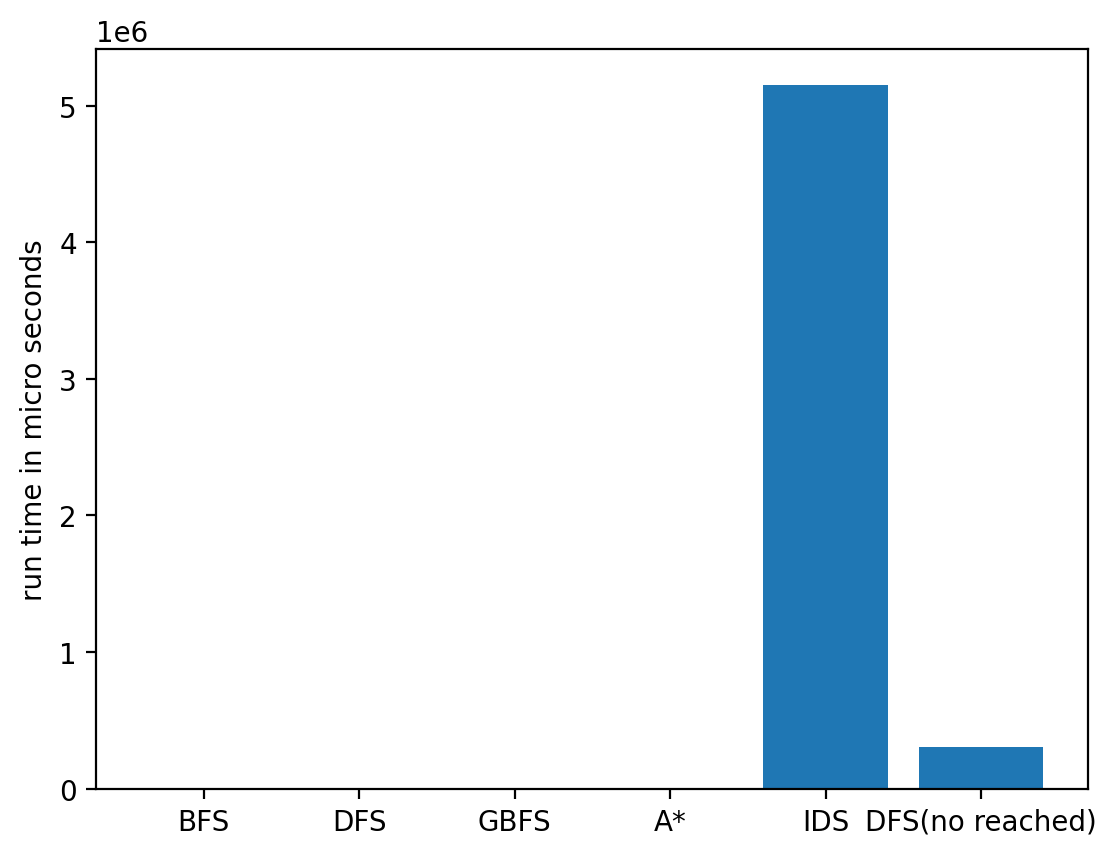

In [22]:
import matplotlib.pyplot as plt

plt.bar(df.columns, height = df.iloc[0])
plt.ylabel("run time in micro seconds")
plt.show()